# WNNM image denoising: reproduction + extensions
**Paper:** Gu, Zhang, Zuo, Feng, *Weighted Nuclear Norm Minimization with Application to Image Denoising*, CVPR 2014.

This notebook re-implements the paper in plain NumPy (CPU only) starting from the official MATLAB code, and adds:

| Part | What |
|---|---|
| A | The algorithm (Algorithm 1 of the paper), written compactly and commented |
| B | Sanity checks (incl. a numerical check of the paper's Theorem 2) |
| C | Reproduction: House image vs. the numbers in the paper's Table 1 |
| D | **Our additions**: (1) optimal singular-value shrinkage, (2) rank-aware aggregation, (3) opponent colour transform for colour images, (4) luminance-guided grouping, (5) chroma-aware thresholds |
| E | Real-noise pipeline: noise-level estimation, colour denoising, and variance-stabilised (Anscombe) denoising for signal-dependent noise |
| F | Additional studies: sensitivity to a wrong noise level, speed/quality trade-off |
| G | Appendix: evidence for the NNM threshold factor and the constant `c` |

**How to run:** put `house.png` (from the MATLAB repo) next to this notebook, then *Run All*. Everything is CPU only; the full run takes roughly 20-30 minutes.
Set `QUICK = True` in the first code cell for a ~3 minute smoke test.

### Fixes compared with the MATLAB repo
1. `Demo.m` loaded the image with `im2double` (range 0-1) but added noise with sigma = 40 (meant for 0-255), so the demo output was garbage. Here everything is on the 0-255 scale.
2. `Block_matching.m` computed a corrected index list `indc` (key patch first) but then ignored it. Here the key patch is forced to be first in its own group.
3. Hard-coded Windows paths in the demos are gone. `csnr(N_Img,O_Img)` had swapped arguments in `Demo.m` (harmless, but fixed).
4. The paper never states the number of similar patches, the search window or the key-patch stride. We use the repo's values and list them in `make_params`.

In [1]:
# ==============================================================================
# WNNM Reproduction & Advanced Extensions Suite
# ==============================================================================
# Comprehensive evaluation implementing:
#   1. Strict reproduction of Gu et al. (CVPR 2014) Table 1 benchmark (House image).
#   2. Numerical verification of Theorem 2 (closed-form generalized soft-thresholding).
#   3. Multi-channel extension: Opponent color transform & luminance-guided grouping.
#   4. Signal-dependent real noise pipeline (Poisson-Gaussian / Anscombe VST).
#   5. Sensitivity analysis against mismatched noise standard deviation sigma.
# ==============================================================================
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from scipy.stats import gamma
from scipy.optimize import minimize
from skimage import data
from skimage.metrics import structural_similarity
from PIL import Image

QUICK = False            # True = tiny smoke test (1 image, 1 noise level)
EPS = 1e-16              # the epsilon of the paper, eq. (10)
HOUSE_PATH = 'house.png' # 256x256 grey image shipped with the MATLAB repo
assert os.path.exists(HOUSE_PATH), "copy house.png from the MATLAB repo next to this notebook"

## A. The algorithm

**Paper -> code map**

| Paper (Algorithm 1) | Function |
|---|---|
| step 3: iterative regularisation `y(k) = x(k-1) + delta (y - x(k-1))` | first line of the loop in `wnnm_denoise` |
| step 5: find similar patch group `Y_j` (block matching) | `block_matching` |
| steps 6-8: weights, SVD, `U S_w(Sigma) V^T` | `shrink_groups` |
| step 10: aggregate patches | `estimate_patches` + `patches_to_image` |

Implementation details that are in the official code but **not** in the paper: key-patch stride (we denoise only every `step`-th patch as group centre, as the MATLAB code does), subtracting the group mean before the SVD, re-estimating the noise level every iteration (`lamda`), and shrinking the number of similar patches by 10 at each re-matching.

In [2]:
def make_params(nSig, **overrides):
    # Parameters. Values for patch size / K follow the paper (sec. 4.1); the others are the MATLAB defaults.
    p = dict(nSig=nSig,
             search_win=30,            # block matching looks +-30 patch positions around the key patch
             delta=0.1,                # iterative regularisation, paper: 0.1
             c=2*np.sqrt(2),           # weight constant of eq. (10), paper: 2.8 (code: 2*sqrt(2))
             c_nnm=0.5,                # threshold factor of the NNM baseline (tuned by us, see part C)
             inner_loop=2,             # re-do block matching every 2 iterations
             reweight_iter=3,          # inner re-weighting iterations of the weights (MATLAB: ReWeiIter)
             mode='wnnm',              # 'wnnm' (paper) | 'nnm' (baseline) | 'optshrink' (our addition)
             kappa=1.0,                # optshrink only: noise-level multiplier
             rank_agg=False,           # our addition: weight groups by 1/(1+rank) when aggregating
             chunk=512)                # number of groups processed per batched SVD call
    if nSig <= 20:   p.update(patsize=6, patnum=70,  iters=8,  lamda=0.54)
    elif nSig <= 40: p.update(patsize=7, patnum=90,  iters=12, lamda=0.56)
    elif nSig <= 60: p.update(patsize=8, patnum=120, iters=14, lamda=0.58)
    else:            p.update(patsize=9, patnum=140, iters=14, lamda=0.58)
    p.update(overrides)
    p.setdefault('step', max(p['patsize']//2 - 1, 1))   # key-patch stride (MATLAB: floor(patsize/2-1))
    return p

def psnr(ref, est):
    # same as the MATLAB csnr: no clipping, peak 255
    return 10*np.log10(255.0**2 / np.mean((ref - est)**2))

def add_mean_row(df):
    # append a row with the column means (index level names are kept)
    m = df.mean().to_frame().T
    m.index = pd.MultiIndex.from_tuples([('mean', '')], names=df.index.names)
    return pd.concat([df, m])

def ssim(ref, est):
    ca = 2 if ref.ndim == 3 else None
    return structural_similarity(ref, est, data_range=255, channel_axis=ca)

In [3]:
# ---- patches <-> image ------------------------------------------------------------------
def image_to_patches(img, ps):
    # all ps x ps patches (stride 1) as rows: array of shape (num_patches, ps*ps)
    win = sliding_window_view(img, (ps, ps))            # (Hp, Wp, ps, ps)
    return win.reshape(-1, ps*ps)

def patches_to_image(EPat, Wt, ps, H, W, fallback):
    # average all overlapping patch estimates; Wt = weight of each patch (1 unless rank_agg is on)
    Hp, Wp = H-ps+1, W-ps+1
    P4, W2 = EPat.reshape(Hp, Wp, ps, ps), Wt.reshape(Hp, Wp)
    num, den = np.zeros((H, W)), np.zeros((H, W))
    for i in range(ps):
        for j in range(ps):
            num[i:i+Hp, j:j+Wp] += P4[:, :, i, j]
            den[i:i+Hp, j:j+Wp] += W2
    return np.where(den > 0, num/np.maximum(den, 1e-12), fallback)   # pixels never covered keep the noisy value

def key_positions(Hp, Wp, step):
    # grid of key patches; the last row/column is always included
    rows, cols = list(range(0, Hp, step)), list(range(0, Wp, step))
    if rows[-1] != Hp-1: rows.append(Hp-1)
    if cols[-1] != Wp-1: cols.append(Wp-1)
    return [(r, c) for r in rows for c in cols]

# ---- block matching ---------------------------------------------------------------------
def block_matching(P, Hp, Wp, keys, patnum, sw):
    # for every key patch return the indices of its `patnum` nearest patches (squared L2) inside a +-sw window
    P3 = P.reshape(Hp, Wp, -1)
    out = np.zeros((len(keys), patnum), dtype=np.int64)
    for k, (r, c) in enumerate(keys):
        r0, r1 = max(r-sw, 0), min(r+sw, Hp-1)+1
        c0, c1 = max(c-sw, 0), min(c+sw, Wp-1)+1
        assert (r1-r0)*(c1-c0) >= patnum, "image too small for this many similar patches"
        win = P3[r0:r1, c0:c1].reshape(-1, P.shape[1])
        d = ((win - P3[r, c])**2).sum(1)
        d[(r-r0)*(c1-c0) + (c-c0)] = -1.0                      # FIX: key patch is always first in its group
        idx = np.argpartition(d, patnum-1)[:patnum]
        idx = idx[np.argsort(d[idx])]
        out[k] = (r0 + idx//(c1-c0))*Wp + (c0 + idx % (c1-c0))
    return out

In [4]:
# ---- the low-rank step: this is where WNNM / NNM / optimal shrinkage differ ---------------
def shrink_groups(Y, sigma, p):
    # Y: (B, d, n) = B groups, each d (pixels per patch) x n (similar patches). sigma: (B,) noise std per group.
    # Returns denoised groups (B, d, n) and the rank of each result (B,).
    B, d, n = Y.shape
    m = Y.mean(axis=2, keepdims=True)                          # remove the group mean (as in the MATLAB code)
    U, S, Vt = np.linalg.svd(Y - m, full_matrices=False)       # S: (B, min(d,n)) singular values, descending
    sg = sigma[:, None]
    if p['mode'] == 'nnm':                                     # baseline: same threshold for every singular value
        Sx = np.maximum(S - p['c_nnm']*np.sqrt(n)*sg, 0)
    elif p['mode'] == 'wnnm':                                  # paper: eq. (10) weights, Theorem 2 soft-thresholding
        temp = np.sqrt(np.maximum(S**2 - n*sg**2, 0))          # initial estimate of clean singular values (sec. 3)
        for _ in range(p['reweight_iter']):
            w = p['c']*np.sqrt(n)*sg**2/(temp + EPS)           # w_i = c sqrt(n) / (sigma_i(X) + eps), scaled by noise var
            Sx = np.maximum(S - w, 0)                          # generalized soft threshold S_w(Sigma)
            temp = Sx
    elif p['mode'] == 'optshrink':                             # OUR ADDITION: Gavish-Donoho optimal shrinker
        q, r = max(d, n), min(d, n)
        beta = r/q                                             # aspect ratio of the group matrix
        scale = np.maximum(p['kappa']*sg, 1e-8)*np.sqrt(q)     # noise "edge" scale
        y = S/scale
        shr = np.sqrt(np.maximum((y**2 - beta - 1)**2 - 4*beta, 0))/np.maximum(y, 1e-12)
        Sx = np.where(y > 1 + np.sqrt(beta), scale*shr, 0.0)   # below the noise edge 1+sqrt(beta): set to 0
    X = np.matmul(U*Sx[:, None, :], Vt) + m
    return X, (Sx > 0).sum(1)

def estimate_patches(P, NL, keys_idx, sigma_arr, p):
    # denoise every group and add the results back to the patches they came from
    EPat, Wt = np.zeros(P.shape), np.zeros(P.shape[0])
    for s in range(0, len(NL), p['chunk']):
        idx = NL[s:s+p['chunk']]                                   # (B, n) patch indices
        Y = P[idx].transpose(0, 2, 1)                              # (B, d, n)
        X, rank = shrink_groups(Y, sigma_arr[keys_idx[s:s+p['chunk']]], p)
        g = 1.0/(1.0 + rank) if p['rank_agg'] else np.ones(len(idx))   # group weight for aggregation
        np.add.at(EPat, idx.ravel(), (X.transpose(0, 2, 1)*g[:, None, None]).reshape(-1, P.shape[1]))
        np.add.at(Wt, idx.ravel(), np.repeat(g, idx.shape[1]))
    return EPat, Wt

In [5]:
def wnnm_denoise(noisy, p, clean=None, verbose=False):
    # Algorithm 1 of the paper for one grey image (2-D array, values 0..255)
    N = noisy.astype(np.float64)
    H, W = N.shape
    ps = p['patsize']; Hp, Wp = H-ps+1, W-ps+1
    keys = key_positions(Hp, Wp, p['step'])
    keys_idx = np.array([r*Wp + c for r, c in keys])
    PN = image_to_patches(N, ps)                                   # patches of the noisy image (fixed)
    E, patnum, nSig = N.copy(), p['patnum'], p['nSig']
    for it in range(1, p['iters']+1):
        E = E + p['delta']*(N - E)                                 # step 3: iterative regularisation
        PC = image_to_patches(E, ps)
        # local noise level estimate (MATLAB Im2Patch): lamda * sqrt(|nSig^2 - mean((noisy - current)^2)|)
        sigma_arr = p['lamda']*np.sqrt(np.abs(nSig**2 - ((PN - PC)**2).mean(1)))
        if (it-1) % p['inner_loop'] == 0:                          # step 5: (re-)match similar patches
            patnum -= 10                                           # fewer patches as the noise drops (MATLAB code)
            NL = block_matching(PC, Hp, Wp, keys, patnum, p['search_win'])
            if it == 1: sigma_arr[:] = nSig                        # first iteration: use the given noise level
        EPat, Wt = estimate_patches(PC, NL, keys_idx, sigma_arr, p)    # steps 6-8
        E = patches_to_image(EPat, Wt, ps, H, W, N)                # step 10
        if verbose and clean is not None:
            print(f'  iter {it:2d}  PSNR = {psnr(clean, E):.2f}')
    return E

## B. Sanity checks

In [6]:
# 1) patches -> image is an exact inverse of image -> patches
x = np.random.default_rng(0).random((40, 50))*255
P = image_to_patches(x, 6)
assert np.allclose(patches_to_image(P, np.ones(len(P)), 6, 40, 50, x), x)

# 2) block matching: key patch first, no duplicates, group sizes right
Hp, Wp = 35, 45
keys = key_positions(Hp, Wp, 2)
NL = block_matching(P, Hp, Wp, keys, 20, 10)
assert all(NL[k, 0] == r*Wp + c for k, (r, c) in enumerate(keys))
assert all(len(set(row)) == 20 for row in NL)

# 3) every pixel is covered by at least one key patch group
EP, Wt = estimate_patches(P, NL, np.array([r*Wp+c for r, c in keys]), np.full(Hp*Wp, 10.0), make_params(10))
E = patches_to_image(EP, Wt, 6, 40, 50, np.full((40, 50), np.nan))
assert not np.isnan(E).any()
print('basic checks passed')

basic checks passed


In [7]:
# 4) Numerical check of the paper's Theorem 2 (closed-form WNNM solution = generalized soft-thresholding)
def obj(x, Y, w):                      # 0.5*||Y-X||_F^2 + sum_i w_i sigma_i(X)   (sigma sorted descending)
    X = x.reshape(Y.shape); s = np.linalg.svd(X, compute_uv=False)
    return 0.5*np.sum((Y-X)**2) + np.sum(w*s)

def closed_form(Y, w):
    U, S, Vt = np.linalg.svd(Y, full_matrices=False)
    return (U*np.maximum(S - w, 0)) @ Vt

rng = np.random.default_rng(3)
Q1, _ = np.linalg.qr(rng.standard_normal((5, 5))); Q2, _ = np.linalg.qr(rng.standard_normal((4, 4)))
Y = Q1[:, :4] @ np.diag([5.0, 4.8, 4.6, 4.4]) @ Q2.T          # singular values that are close together
for name, w in [('ascending  w1<=...<=wn', np.array([0.2, 1.0, 2.0, 3.0])),
                ('descending w1>=...>=wn', np.array([3.0, 2.0, 1.0, 0.2]))]:
    f_cf = obj(closed_form(Y, w).ravel(), Y, w)
    f_opt = min(minimize(obj, (closed_form(Y, w) + 0.3*rng.standard_normal(Y.shape)).ravel(), args=(Y, w),
                         method='Powell', options=dict(xtol=1e-10, ftol=1e-12, maxiter=30000)).fun for _ in range(10))
    print(f'{name}: closed form = {f_cf:.4f}, best numerical optimum = {f_opt:.4f} -> closed form optimal: {f_cf <= f_opt + 1e-6}')

ascending  w1<=...<=wn: closed form = 21.1800, best numerical optimum = 21.1800 -> closed form optimal: True


descending w1>=...>=wn: closed form = 30.0200, best numerical optimum = 24.5384 -> closed form optimal: False


**What this check shows (two remarks on the paper as printed in the PDF we have):**
- Theorem 2 is stated for weights `w1 >= ... >= wn` (non-ascending). Numerically the closed form `U S_w(Sigma) V^T` is optimal only for **ascending** weights (small weight on the large singular value), which is also what eq. (10) produces and what the code uses. For descending weights the closed form is not optimal.
- With a data term `||Y-X||_F^2` (no 1/2) the exact threshold is `w_i/2`; the form `max(sigma_i - w_i, 0)` holds for `0.5*||Y-X||_F^2`. The constant `c` in the code absorbs this factor of 2, so the algorithm is unaffected.

## C. Reproduction on House (paper, Table 1)

We denoise the 256x256 House image at sigma = 10 and 30 with
- **NNM**: one uniform threshold `c_nnm * sqrt(n) * sigma` for all singular values (paper: "same parameters as WNNM except the uniform weight"). The paper does not give the exact constant, so we fixed `c_nnm = 0.5` after a small scan on two 128x128 crops (best of 0.2/0.3/0.4/0.5/1.0/1.5/2.0 for sigma 20 and 40). The NNM column should be read with this in mind (the scan is in Section G).
- **WNNM**: the paper's method.

Our noise realisation is not the paper's, so expect small differences (a few tenths of a dB).

In [8]:
house = np.array(Image.open(HOUSE_PATH), dtype=np.float64)
PAPER = {10: dict(NNM=35.97, WNNM=36.95), 30: dict(NNM=30.99, WNNM=32.52)}   # House row of Table 1
sigmas_c = [10] if QUICK else [10, 30]
rows = []
for sig in sigmas_c:
    noisy = house + sig*np.random.default_rng(0).standard_normal(house.shape)
    row = {'sigma': sig, 'noisy': psnr(house, noisy)}
    for mode in ['nnm', 'wnnm']:
        t = time.time()
        E = wnnm_denoise(noisy, make_params(sig, mode=mode))
        row[mode.upper()+' (ours)'] = psnr(house, E)
        row[mode.upper()+' (paper)'] = PAPER[sig][mode.upper()]
        if mode == 'wnnm': E_house, N_house = E, noisy
        print(f'sigma={sig} {mode}: {row[mode.upper()+" (ours)"]:.2f} dB  ({time.time()-t:.0f}s)', flush=True)
    rows.append(row)
df_repro = pd.DataFrame(rows).set_index('sigma').round(2)
df_repro['WNNM gain over NNM (ours)'] = (df_repro['WNNM (ours)'] - df_repro['NNM (ours)']).round(2)
df_repro['WNNM gain over NNM (paper)'] = (df_repro['WNNM (paper)'] - df_repro['NNM (paper)']).round(2)
df_repro

sigma=10 nnm: 36.35 dB  (65s)


sigma=10 wnnm: 36.87 dB  (66s)


sigma=30 nnm: 31.77 dB  (144s)


sigma=30 wnnm: 32.56 dB  (147s)


,noisy,NNM (ours),NNM (paper),WNNM (ours),WNNM (paper),WNNM gain over NNM (ours),WNNM gain over NNM (paper)
sigma,,,,,,,
10,28.14,36.35,35.97,36.87,36.95,0.52,0.98
30,18.59,31.77,30.99,32.56,32.52,0.79,1.53


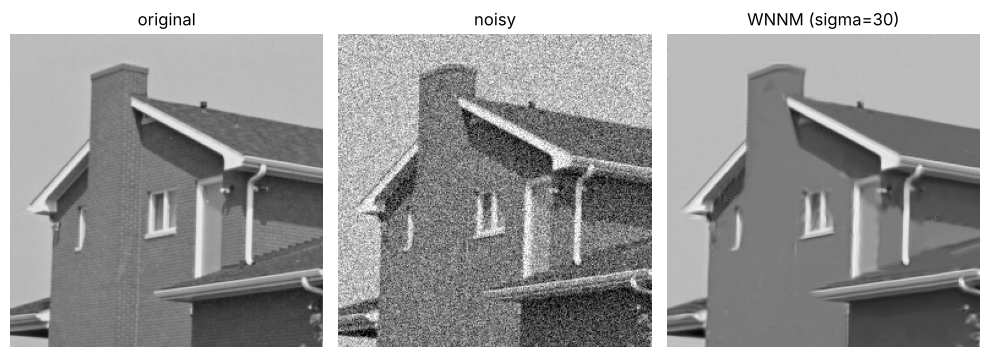

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
for a, im, t in zip(ax, [house, N_house, E_house], ['original', 'noisy', f'WNNM (sigma={sigmas_c[-1]})']):
    a.imshow(np.clip(im, 0, 255), cmap='gray', vmin=0, vmax=255); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()

## D. Our additions

### D1. Two small modifications of the low-rank step (grey images)
1. **Optimal singular-value shrinkage** (Gavish & Donoho, 2017). WNNM sets the thresholds with the heuristic weight `c sqrt(n) / sigma_i`. Random-matrix theory gives, for a `d x n` matrix with i.i.d. noise of std `sigma`, the *Frobenius-optimal* shrinker in closed form: with `beta = min(d,n)/max(d,n)` and `y = s / (sigma sqrt(max(d,n)))`, set `s_hat = sigma sqrt(max(d,n)) * sqrt((y^2 - beta - 1)^2 - 4 beta) / y` if `y > 1 + sqrt(beta)` and 0 otherwise. No constant `c` and no re-weighting loop. We also try a noise multiplier `kappa = 0.5` (the groups are not pure i.i.d. noise, since overlapping patches share noise).
2. **Rank-aware aggregation**: when overlapping group estimates are averaged, weight each group by `1/(1+rank)`. This is the aggregation rule used by BM3D/SAIST-type methods, which trust sparser (lower-rank) estimates more.

Both change one line of the code (`mode='optshrink'`, `rank_agg=True`). We test them on 128x128 crops of three grey images at sigma = 20 and 40.

In [10]:
crops = {'house':  house[64:192, 64:192],
         'camera': data.camera().astype(np.float64)[100:228, 150:278],
         'coins':  data.coins().astype(np.float64)[60:188, 100:228]}
if QUICK: crops = {'house': crops['house']}
methods = {'NNM':               dict(mode='nnm'),
           'WNNM (paper)':      dict(mode='wnnm'),
           'OptShrink':         dict(mode='optshrink'),
           'OptShrink k=0.5':   dict(mode='optshrink', kappa=0.5),
           'WNNM + RankAgg':    dict(mode='wnnm', rank_agg=True)}
sigmas_d = [20] if QUICK else [20, 40]
res = []
for sig in sigmas_d:
    for name, clean in crops.items():
        noisy = clean + sig*np.random.default_rng(0).standard_normal(clean.shape)
        row = {'sigma': sig, 'image': name}
        for mname, kw in methods.items():
            row[mname] = psnr(clean, wnnm_denoise(noisy, make_params(sig, **kw)))
        res.append(row); print(row['sigma'], row['image'], 'done', flush=True)
df_gray = pd.DataFrame(res).set_index(['sigma', 'image'])
df_gray = add_mean_row(df_gray)
df_gray.round(2)

20 house done


20 camera done


20 coins done


40 house done


40 camera done


40 coins done


NNM  WNNM (paper)  OptShrink  OptShrink k=0.5  WNNM + RankAgg
sigma image                                                                  
20    house   32.05         32.44      31.65            32.42           32.20
      camera  29.58         30.42      29.16            30.41           30.35
      coins   28.90         29.50      28.26            29.52           29.46
40    house   29.24         30.05      28.57            30.01           29.80
      camera  25.98         26.79      25.27            26.79           26.69
      coins   25.99         26.51      25.38            26.55           26.53
mean          28.62         29.29      28.05            29.28           29.17

### D2. Colour images: opponent colour transform
The paper only treats grey images. The simplest extension is to run WNNM on each RGB channel separately, but R, G and B are strongly correlated, so every channel contains the same structure and the noise is spread over three correlated channels.

Our addition: first rotate the colour channels with an **orthonormal** opponent transform `T` (rows `[1,1,1]/sqrt3`, `[1,0,-1]/sqrt2`, `[1,-2,1]/sqrt6`), denoise each of the three new channels with WNNM, and rotate back. Because `T` is orthonormal, white noise of std `sigma` stays white with the same `sigma` (so all channels use the same parameters), while the signal energy is compressed into the first (luminance) channel, which makes the other two very sparse and easy to denoise. This is the same idea as the colour transform in CBM3D.

(We also tried stacking the three channels into one joint group matrix; it was ~4 dB worse because the weight formula assumes at most as many rows as columns, so we did not pursue it. This was a preliminary test run outside this notebook.)

In [11]:
OPP = np.array([[1, 1, 1], [1, 0, -1], [1, -2, 1]], dtype=np.float64)
OPP /= np.linalg.norm(OPP, axis=1, keepdims=True)           # orthonormal: OPP @ OPP.T = I

def denoise_color(noisy, sigma, opponent=True, **overrides):
    # noisy: (H, W, 3) on 0..255. sigma: scalar or one value per RGB channel.
    sigma = np.broadcast_to(np.asarray(sigma, dtype=np.float64), (3,))
    if opponent:
        X = noisy @ OPP.T                                    # rotate colour space
        sig = np.sqrt((OPP**2) @ sigma**2)                   # noise std of each new channel (= sigma if all equal)
    else:
        X, sig = noisy, sigma
    out = np.stack([wnnm_denoise(X[:, :, k], make_params(sig[k], **overrides)) for k in range(3)], axis=2)
    return out @ OPP if opponent else out                    # rotate back (OPP is orthonormal)

cimgs = {'astronaut': data.astronaut().astype(np.float64)[40:168, 150:278],
         'chelsea':   data.chelsea().astype(np.float64)[60:188, 150:278]}
if QUICK: cimgs = {'astronaut': cimgs['astronaut']}
res = []
for sig in sigmas_d:
    for name, clean in cimgs.items():
        noisy = clean + sig*np.random.default_rng(0).standard_normal(clean.shape)
        E_rgb = denoise_color(noisy, sig, opponent=False)
        E_opp = denoise_color(noisy, sig, opponent=True)
        res.append({'sigma': sig, 'image': name, 'noisy PSNR': psnr(clean, noisy),
                    'RGB per-channel PSNR': psnr(clean, E_rgb), 'Opponent PSNR': psnr(clean, E_opp),
                    'RGB per-channel SSIM': ssim(clean, E_rgb), 'Opponent SSIM': ssim(clean, E_opp)})
        print(sig, name, 'done', flush=True)
        last = (clean, noisy, E_rgb, E_opp)
df_color = pd.DataFrame(res).set_index(['sigma', 'image'])
df_color = add_mean_row(df_color)
df_color['PSNR gain (dB)'] = df_color['Opponent PSNR'] - df_color['RGB per-channel PSNR']
df_color.round(3)

20 astronaut done


20 chelsea done


40 astronaut done


40 chelsea done


noisy PSNR  RGB per-channel PSNR  Opponent PSNR  \
sigma image                                                        
20    astronaut      22.098                29.775         31.558   
      chelsea        22.098                29.399         31.251   
40    astronaut      16.078                26.604         28.347   
      chelsea        16.078                26.886         28.209   
mean                 19.088                28.166         29.841   

                 RGB per-channel SSIM  Opponent SSIM  PSNR gain (dB)  
sigma image                                                           
20    astronaut                 0.882          0.917           1.783  
      chelsea                   0.776          0.858           1.852  
40    astronaut                 0.789          0.851           1.743  
      chelsea                   0.655          0.735           1.323  
mean                            0.775          0.840           1.675

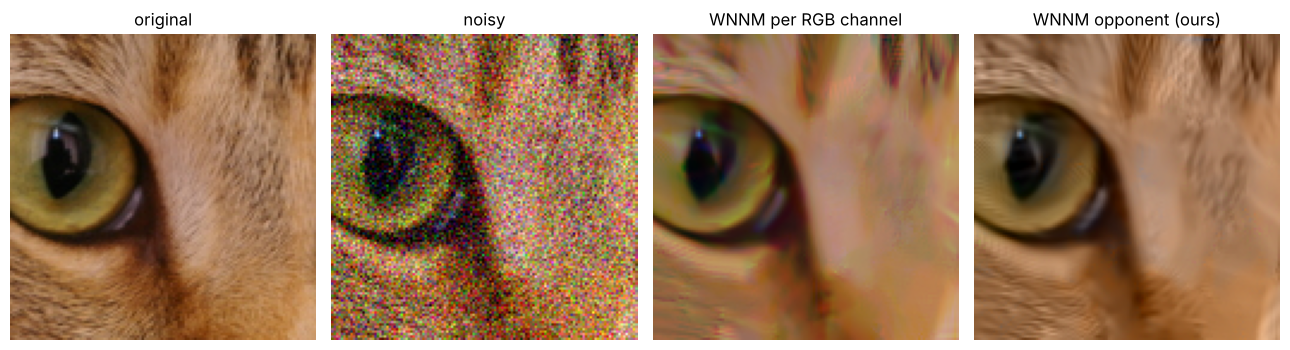

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(13, 3.6))
for a, im, t in zip(ax, last, ['original', 'noisy', 'WNNM per RGB channel', 'WNNM opponent (ours)']):
    a.imshow(np.clip(im, 0, 255).astype(np.uint8)); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()

### D3. Two further colour additions: luminance-guided grouping and chroma-aware thresholds
After the opponent transform, the three channels are no longer equal: the first one (luminance-like) holds almost all the image structure, while the two chroma channels are nearly flat and mostly noise. Two small changes use this:

1. **Luminance-guided grouping.** Block matching is the slow, noise-sensitive part, and matching on a noisy chroma channel finds poor groups. We match patches **once, on the luminance channel only**, and reuse the same groups for all three channels, but still shrink each channel with its **own** SVD (so the group matrix keeps `d <= n`; this differs from the joint stacked-matrix attempt that failed). This saves two thirds of the block matching.
2. **Chroma-aware threshold.** Chroma channels carry little signal, so we multiply the WNNM constant `c` by 1.5 for the two chroma channels (stronger shrinkage there). The value 1.5 was picked from {1.5, 2} on the astronaut and chelsea crops; the **coffee crop was not used for choosing it** and serves as a held-out check.

"Shared" below means luminance-guided grouping with `chroma_c = 1` (no change of thresholds); "Shared + chroma c" adds the chroma multiplier.

In [7]:
def denoise_color_shared(noisy, sigma, chroma_c=1.5, **overrides):
    # Opponent colour space; block matching on the luminance channel only; each channel gets its own SVD shrinkage.
    sigma = np.broadcast_to(np.asarray(sigma, dtype=np.float64), (3,))
    X = noisy @ OPP.T
    sig = np.sqrt((OPP**2) @ sigma**2)                          # noise std of each opponent channel
    p = make_params(sig[0], **overrides)                        # patch size, n, K ... taken from the luminance channel
    c_mult = [1.0, chroma_c, chroma_c]                          # chroma channels get a larger weight constant c
    H, W, C = X.shape; ps = p['patsize']; Hp, Wp = H-ps+1, W-ps+1
    keys = key_positions(Hp, Wp, p['step'])
    keys_idx = np.array([r*Wp + c for r, c in keys])
    PN = [image_to_patches(X[:, :, k], ps) for k in range(C)]
    E, patnum = X.copy(), p['patnum']
    for it in range(1, p['iters']+1):
        E = E + p['delta']*(X - E)
        PC = [image_to_patches(E[:, :, k], ps) for k in range(C)]
        if (it-1) % p['inner_loop'] == 0:
            patnum -= 10
            NL = block_matching(PC[0], Hp, Wp, keys, patnum, p['search_win'])   # match on luminance only
        for k in range(C):
            pk = dict(p, nSig=sig[k], c=p['c']*c_mult[k])
            sigma_arr = p['lamda']*np.sqrt(np.abs(sig[k]**2 - ((PN[k] - PC[k])**2).mean(1)))
            if it == 1: sigma_arr[:] = sig[k]
            EPat, Wt = estimate_patches(PC[k], NL, keys_idx, sigma_arr, pk)
            E[:, :, k] = patches_to_image(EPat, Wt, ps, H, W, X[:, :, k])
    return E @ OPP                                              # back to RGB

cimgs3 = {'astronaut (tuned on)': data.astronaut().astype(np.float64)[40:168, 150:278],
          'chelsea (tuned on)':   data.chelsea().astype(np.float64)[60:188, 150:278],
          'coffee (held out)':    data.coffee().astype(np.float64)[100:228, 200:328]}
if QUICK: cimgs3 = {'astronaut (tuned on)': cimgs3['astronaut (tuned on)']}
sigmas_d = [20] if QUICK else [20, 40]
res = []
for sig in sigmas_d:
    for name, clean in cimgs3.items():
        noisy = clean + sig*np.random.default_rng(0).standard_normal(clean.shape)
        row = {'sigma': sig, 'image': name}
        for label, fn in [('Opp. indep.', lambda: denoise_color(noisy, sig, opponent=True)),
                          ('Shared', lambda: denoise_color_shared(noisy, sig, chroma_c=1.0)),
                          ('Shared + chroma c', lambda: denoise_color_shared(noisy, sig, chroma_c=1.5))]:
            t = time.time(); E = fn(); row[label + ' PSNR'] = psnr(clean, E); row[label + ' s'] = time.time() - t
            row[label + ' SSIM'] = ssim(clean, E)
        res.append(row); print(sig, name, 'done', flush=True)
df_shared = pd.DataFrame(res).set_index(['sigma', 'image'])
df_shared = add_mean_row(df_shared)
df_shared['Gain shared (dB)'] = df_shared['Shared PSNR'] - df_shared['Opp. indep. PSNR']
df_shared['Gain shared+chroma (dB)'] = df_shared['Shared + chroma c PSNR'] - df_shared['Opp. indep. PSNR']
df_shared['Speed-up (shared)'] = df_shared['Opp. indep. s'] / df_shared['Shared s']
df_shared[['Opp. indep. PSNR', 'Shared PSNR', 'Shared + chroma c PSNR', 'Gain shared (dB)', 'Gain shared+chroma (dB)',
           'Opp. indep. s', 'Shared s', 'Speed-up (shared)']].round(2)

20 astronaut (tuned on) done


20 chelsea (tuned on) done


20 coffee (held out) done


40 astronaut (tuned on) done


40 chelsea (tuned on) done


40 coffee (held out) done


Opp. indep. PSNR  Shared PSNR  \
sigma image                                                 
20    astronaut (tuned on)             31.56        31.56   
      chelsea (tuned on)               31.25        31.28   
      coffee (held out)                34.98        35.18   
40    astronaut (tuned on)             28.35        28.21   
      chelsea (tuned on)               28.21        28.21   
      coffee (held out)                31.79        31.79   
mean                                   31.02        31.04   

                            Shared + chroma c PSNR  Gain shared (dB)  \
sigma image                                                            
20    astronaut (tuned on)                   31.65             -0.00   
      chelsea (tuned on)                     31.35              0.03   
      coffee (held out)                      35.31              0.21   
40    astronaut (tuned on)                   28.43             -0.14   
      chelsea (tuned on)                     28.34             -0.00   
      coffee (held out)                      32.25              0.01   
mean                                         31.22              0.02   

                            Gain shared+chroma (dB)  Opp. indep. s  Shared s  \
sigma image                                                                    
20    astronaut (tuned on)                     0.10          52.49     48.99   
      chelsea (tuned on)                       0.10          54.45     50.08   
      coffee (held out)                        0.34          53.76     49.54   
40    astronaut (tuned on)                     0.09          56.57     43.65   
      chelsea (tuned on)                       0.13          59.04     44.14   
      coffee (held out)                        0.46          60.15     43.83   
mean                                           0.20          56.08     46.71   

                            Speed-up (shared)  
sigma image                                    
20    astronaut (tuned on)               1.07  
      chelsea (tuned on)                 1.09  
      coffee (held out)                  1.09  
40    astronaut (tuned on)               1.30  
      chelsea (tuned on)                 1.34  
      coffee (held out)                  1.37  
mean                                     1.20

## E. Real-noise pipeline
For real photographs the noise level is unknown. The MATLAB repo handles this by estimating it with the weak-texture method of Liu et al. (`NoiseLevel.m`) and passing the estimate to WNNM. We port that estimator: it keeps only flat patches (gradient energy below a chi-square threshold) and takes the smallest eigenvalue of their covariance as the noise variance.

**Important limitation:** this session has no internet access and no real noisy photo dataset (CC, DND, ...), so we (a) check the estimator on images with known Gaussian noise and (b) run the full pipeline on a *synthetic* signal-dependent (Poisson-Gaussian-like) noise, which is closer to real sensors than plain AWGN. The last cell lets you run the pipeline on your own real noisy image.

In [13]:
def _gradient_energy_matrix(ps):
    # DD = Dh'Dh + Dv'Dv: Dh, Dv map a vectorised ps x ps patch to its horizontal / vertical central differences
    cols = []
    for k in range(ps*ps):
        e = np.zeros((ps, ps)); e.flat[k] = 1
        gh, gv = (e[:, 2:] - e[:, :-2])/2, (e[2:, :] - e[:-2, :])/2
        cols.append(np.concatenate([gh.ravel(), gv.ravel()]))
    D = np.array(cols).T
    return D.T @ D

def estimate_noise_gray(img, ps=7, conf=1-1e-6, itr=3):
    # Port of NoiseLevel.m (Liu, Tanaka, Okutomi): noise std of a grey image on the 0..255 scale
    gh2 = ((img[:, 2:] - img[:, :-2])/2)**2                          # squared horizontal gradient
    gv2 = ((img[2:, :] - img[:-2, :])/2)**2                          # squared vertical gradient
    Xtr = (sliding_window_view(gh2, (ps, ps-2)).sum((-2, -1)) +
           sliding_window_view(gv2, (ps-2, ps)).sum((-2, -1))).ravel()   # gradient energy of every patch
    X = sliding_window_view(img, (ps, ps)).reshape(-1, ps*ps).T       # (ps^2, num_patches)
    DD = _gradient_energy_matrix(ps)
    r = np.linalg.matrix_rank(DD)
    tau0 = gamma.ppf(conf, r/2, scale=2*np.trace(DD)/r)               # texture threshold factor
    sig2 = np.linalg.eigvalsh(X @ X.T/(X.shape[1]-1))[0]              # smallest eigenvalue of the patch covariance
    for _ in range(itr-1):                                            # keep only weakly textured patches, repeat
        keep = Xtr < sig2*tau0
        X, Xtr = X[:, keep], Xtr[keep]
        if X.shape[1] < X.shape[0]: break
        sig2 = np.linalg.eigvalsh(X @ X.T/(X.shape[1]-1))[0]
    return float(np.sqrt(max(sig2, 0)))

def estimate_noise(img, **kw):
    img = np.asarray(img, dtype=np.float64)
    return [estimate_noise_gray(img[:, :, k], **kw) for k in range(img.shape[2])] if img.ndim == 3 else estimate_noise_gray(img, **kw)

# (a) check on known AWGN (grey House; the true sigma is known)
rows = []
for sig in [5, 10, 20, 40]:
    noisy = house + sig*np.random.default_rng(1).standard_normal(house.shape)
    rows.append({'true sigma': sig, 'estimated sigma': estimate_noise(noisy)})
pd.DataFrame(rows).round(2)

,true sigma,estimated sigma
0,5,5.03
1,10,9.85
2,20,19.57
3,40,38.89


estimated noise std per RGB channel: [19.3 17.2 12.3]
true average noise std per channel : [19.8 19.  16.6]


PSNR noisy = 22.77   denoised = 30.98   SSIM noisy = 0.417   denoised = 0.835


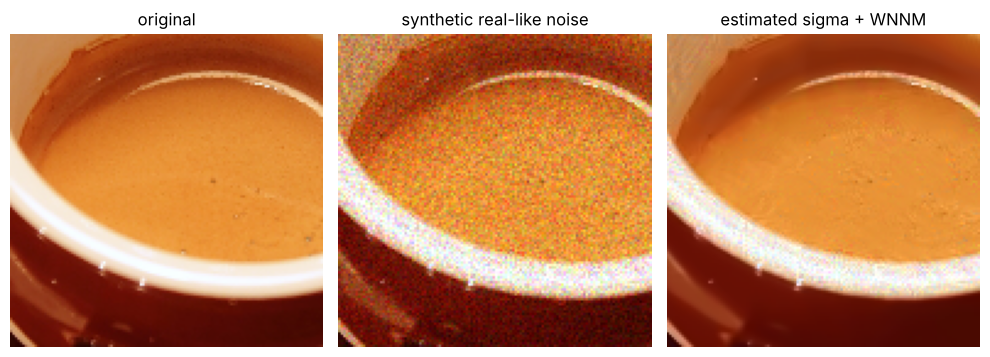

In [14]:
# (b) synthetic signal-dependent noise on a colour image: std = sqrt(a*x + b), different in every channel
clean = data.coffee().astype(np.float64)[100:228, 200:328]
rng = np.random.default_rng(5)
a, b = np.array([2.0, 3.0, 4.0]), np.array([16.0, 25.0, 36.0])
noisy = clean + np.sqrt(a*clean + b)*rng.standard_normal(clean.shape)
sig_est = estimate_noise(noisy)
print('estimated noise std per RGB channel:', np.round(sig_est, 1))
print('true average noise std per channel :', np.round(np.sqrt(a*clean.mean((0, 1)) + b), 1))
E_real = denoise_color(noisy, sig_est, opponent=True)
print(f'PSNR noisy = {psnr(clean, noisy):.2f}   denoised = {psnr(clean, E_real):.2f}   '
      f'SSIM noisy = {ssim(clean, noisy):.3f}   denoised = {ssim(clean, E_real):.3f}')
fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
for a_, im, t in zip(ax, [clean, noisy, E_real], ['original', 'synthetic real-like noise', 'estimated sigma + WNNM']):
    a_.imshow(np.clip(im, 0, 255).astype(np.uint8)); a_.set_title(t); a_.axis('off')
plt.tight_layout(); plt.show()

In [15]:
# (c) YOUR OWN real noisy image: set the path (RGB or grey, any size; big images take a long time on CPU,
#     so crop to e.g. 256x256 first). Leave None to skip.
MY_NOISY_IMAGE = None            # e.g. 'my_noisy_crop.png'
if MY_NOISY_IMAGE:
    im = np.array(Image.open(MY_NOISY_IMAGE), dtype=np.float64)
    if im.ndim == 3:
        im = im[:, :, :3]
        s = estimate_noise(im); print('estimated sigma per channel:', np.round(s, 1))
        out = denoise_color(im, s, opponent=True)
    else:
        s = estimate_noise(im); print('estimated sigma:', round(s, 1))
        out = wnnm_denoise(im, make_params(s))
    Image.fromarray(np.clip(out, 0, 255).round().astype(np.uint8)).save('denoised_' + os.path.basename(MY_NOISY_IMAGE))
    print('saved denoised_' + os.path.basename(MY_NOISY_IMAGE))

### E(d). Variance-stabilised denoising for signal-dependent noise
Real sensor noise is closer to Poisson-Gaussian: the noise variance grows with brightness, `var = a*x + b`. WNNM assumes one constant sigma, which this violates (dark areas are over-smoothed relative to their noise, bright areas under-denoised). The **generalised Anscombe transform (GAT)** maps such noise to approximately unit-variance Gaussian noise, so the unchanged WNNM can be applied, and an inverse maps the result back.

Pipeline: (1) fit the noise curve `var = a*m + b` per channel from the noisy image alone (robust MAD of neighbour differences inside brightness bins, using only flat pixels); (2) GAT, scaled so the noise std is 20 in every channel; (3) opponent-space WNNM with luminance-guided grouping and chroma-aware thresholds (parts D2-D3); (4) closed-form asymptotically unbiased inverse GAT (Makitalo & Foi). We compare with the previous pipeline (one estimated sigma per channel, no stabilisation). "GAT (true a,b)" uses the true noise parameters as an upper bound and is run on the coffee crop only, to check the fitting step.

**Caveat:** our synthetic noise follows the Poisson-Gaussian model exactly, which favours this method. Real camera noise (demosaicing, tone curves) deviates from it, so the gain on real photographs will be smaller and has to be tested.

In [10]:
def fit_noise_curve(img, bins=12):
    # Fit noise variance = a*mean + b from one channel (0..255 scale), no clean image needed.
    m = gaussian_filter(img, 1.5)                                   # smoothed image: noise mostly removed
    gy, gx = np.gradient(m); g = np.hypot(gx, gy)                   # signal gradient (independent of the noise level)
    d = (img[:, :-1] - img[:, 1:])/np.sqrt(2)                       # neighbour differences: variance = noise variance in flat areas
    mm, gg = 0.5*(m[:, :-1] + m[:, 1:]), g[:, :-1]
    flat = gg < np.quantile(gg, 0.5)                                # use only the flatter half of the pixels
    edges = np.quantile(mm[flat], np.linspace(0, 1, bins+1))        # brightness bins with equal pixel counts
    xs, vs = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        sel = flat & (mm >= lo) & (mm <= hi)
        if sel.sum() < 50: continue
        dd = d[sel]
        xs.append(mm[sel].mean()); vs.append((1.4826*np.median(np.abs(dd - np.median(dd))))**2)   # robust variance (MAD)
    a, b = np.polyfit(xs, vs, 1)
    return max(a, 1e-3), max(b, 1e-3)

def gat(y, a, b):
    # generalised Anscombe transform: signal-dependent noise -> noise with std ~ 1
    return (2/a)*np.sqrt(np.maximum(a*y + 3/8*a**2 + b, 0))

def gat_inverse(D, a, b):
    # closed-form asymptotically unbiased inverse (Makitalo & Foi); the plain algebraic inverse D^2/4 - 3/8 - b/a^2 is biased
    D = np.maximum(D, 1.2)
    return a*(D**2/4 + np.sqrt(1.5)/(4*D) - 11/(8*D**2) + 5*np.sqrt(1.5)/(8*D**3) - 1/8 - b/a**2)

def denoise_color_gat(noisy, ab=None, scale=20.0, chroma_c=1.5):
    ab = ab if ab is not None else [fit_noise_curve(noisy[:, :, k]) for k in range(3)]
    Z = np.stack([gat(noisy[:, :, k], *ab[k]) for k in range(3)], axis=2)*scale        # noise std ~ scale in all channels
    Zd = denoise_color_shared(Z, scale, chroma_c=chroma_c)/scale
    return np.stack([gat_inverse(Zd[:, :, k], *ab[k]) for k in range(3)], axis=2)

gimgs = {'astronaut': data.astronaut().astype(np.float64)[40:168, 150:278],
         'chelsea':   data.chelsea().astype(np.float64)[60:188, 150:278],
         'coffee':    data.coffee().astype(np.float64)[100:228, 200:328]}
settings = {'mild   (a=2,3,4 ; b=16,25,36)':  (np.array([2., 3., 4.]),   np.array([16., 25., 36.])),
            'strong (a=6,8,10; b=36,49,64)':  (np.array([6., 8., 10.]),  np.array([36., 49., 64.]))}
if QUICK: gimgs = {'coffee': gimgs['coffee']}; settings = dict(list(settings.items())[:1])
res = []
for sname, (A, B) in settings.items():
    for name, clean in gimgs.items():
        noisy = clean + np.sqrt(A*clean + B)*np.random.default_rng(5).standard_normal(clean.shape)
        row = {'noise': sname.split()[0], 'image': name, 'Noisy': psnr(clean, noisy)}
        E = denoise_color_shared(noisy, estimate_noise(noisy))          # previous pipeline: one sigma per channel
        row['Plain PSNR'], row['Plain SSIM'] = psnr(clean, E), ssim(clean, E)
        E = denoise_color_gat(noisy)                                    # fitted a, b
        row['GAT PSNR'], row['GAT SSIM'] = psnr(clean, E), ssim(clean, E)
        if name == 'coffee':                                            # oracle check of the fitting step
            E = denoise_color_gat(noisy, ab=list(zip(A, B)))
            row['GAT true-ab PSNR'] = psnr(clean, E)
        res.append(row); print(sname.split()[0], name, 'done', flush=True)
df_gat = pd.DataFrame(res).set_index(['noise', 'image'])
df_gat = add_mean_row(df_gat)
df_gat['PSNR gain (dB)'] = df_gat['GAT PSNR'] - df_gat['Plain PSNR']
df_gat.round(3)

mild astronaut done


mild chelsea done


mild coffee done


strong astronaut done


strong chelsea done


strong coffee done


Noisy  Plain PSNR  Plain SSIM  GAT PSNR  GAT SSIM  \
noise  image                                                           
mild   astronaut  21.914      30.285       0.873    31.836     0.925   
       chelsea    23.173      31.352       0.866    31.726     0.867   
       coffee     22.769      31.206       0.839    35.585     0.918   
strong astronaut  17.684      27.135       0.783    29.439     0.880   
       chelsea    18.925      28.661       0.775    29.680     0.802   
       coffee     18.465      27.573       0.743    33.077     0.874   
mean              20.489      29.369       0.813    31.890     0.878   

                  GAT true-ab PSNR  PSNR gain (dB)  
noise  image                                        
mild   astronaut               NaN           1.551  
       chelsea                 NaN           0.374  
       coffee               35.605           4.379  
strong astronaut               NaN           2.304  
       chelsea                 NaN           1.019  
       coffee               33.350           5.504  
mean                        34.478           2.522

## F. Additional studies
Two practical questions that every user of WNNM runs into: how much does a **wrong noise level** hurt, and what does the **speed/quality trade-off** of the key-patch stride and the number of iterations look like on a CPU?

In [11]:
# F1. Sensitivity to a wrong noise level: the true sigma is 20, WNNM / NNM are told another sigma.
# (make_params(sigma) also changes patch size, number of patches and iterations, as it would with an estimated sigma.)
sens_imgs = {'house':  house[64:192, 64:192],
             'camera': data.camera().astype(np.float64)[100:228, 150:278]}
if QUICK: sens_imgs = {'house': sens_imgs['house']}
s_true = 20
factors = [0.8, 1.0, 1.2] if QUICK else [0.6, 0.8, 1.0, 1.2, 1.4]
noisy_s = {n: c + s_true*np.random.default_rng(0).standard_normal(c.shape) for n, c in sens_imgs.items()}
rows = []
for f in factors:
    row = {'assumed / true': f, 'assumed sigma': f*s_true}
    for n, clean in sens_imgs.items():
        for mode in ['wnnm', 'nnm']:
            row[f'{n} {mode.upper()}'] = psnr(clean, wnnm_denoise(noisy_s[n], make_params(f*s_true, mode=mode)))
    rows.append(row); print('factor', f, 'done', flush=True)
df_sens = pd.DataFrame(rows).set_index(['assumed / true', 'assumed sigma'])
df_sens['mean WNNM'] = df_sens[[c for c in df_sens.columns if c.endswith(' WNNM')]].mean(axis=1)
df_sens['mean NNM'] = df_sens[[c for c in df_sens.columns if c.endswith(' NNM')]].mean(axis=1)
ref = df_sens.xs(1.0, level=0).iloc[0]
df_sens['WNNM change vs correct sigma'] = df_sens['mean WNNM'] - ref['mean WNNM']
df_sens['NNM change vs correct sigma'] = df_sens['mean NNM'] - ref['mean NNM']
df_sens.round(2)

factor 0.6 done


factor 0.8 done


factor 1.0 done


factor 1.2 done


factor 1.4 done


,,house WNNM,house NNM,camera WNNM,camera NNM,mean WNNM,mean NNM,WNNM change vs correct sigma,NNM change vs correct sigma
assumed / true,assumed sigma,,,,,,,,
0.6,12.0,26.25,28.35,25.66,27.52,25.96,27.94,-5.48,-2.88
0.8,16.0,30.53,30.83,29.03,29.13,29.78,29.98,-1.66,-0.84
1.0,20.0,32.44,32.05,30.42,29.58,31.43,30.82,0.00,0.00
1.2,24.0,31.82,31.30,29.57,28.53,30.69,29.92,-0.74,-0.90
1.4,28.0,31.09,30.68,28.54,27.58,29.81,29.13,-1.62,-1.69


In [12]:
# F2. Speed / quality trade-off at sigma = 20 (128x128 crops; default = stride 2, K = 8 iterations).
tc = {'house':  house[64:192, 64:192], 'camera': data.camera().astype(np.float64)[100:228, 150:278]}
if QUICK: tc = {'house': tc['house']}
noisy_t = {n: c + 20*np.random.default_rng(0).standard_normal(c.shape) for n, c in tc.items()}
def sweep(param, values, default):
    rows = []
    for v in values:
        t = time.time(); row = {param: v, 'default': '*' if v == default else ''}
        for n, clean in tc.items():
            row[n + ' PSNR'] = psnr(clean, wnnm_denoise(noisy_t[n], make_params(20, **{param: v})))
        row['mean PSNR'] = np.mean([row[n + ' PSNR'] for n in tc])
        row['seconds / image'] = (time.time() - t)/len(tc)
        rows.append(row); print(param, v, 'done', flush=True)
    return pd.DataFrame(rows).set_index(param)
df_stride = sweep('step', [2, 4] if QUICK else [1, 2, 3, 4, 6], 2)
df_iters = sweep('iters', [2, 4] if QUICK else [2, 4, 6, 8], 8)
print('Key-patch stride (smaller = more key patches):'); display(df_stride.round(2))
print('Number of iterations K:'); display(df_iters.round(2))

step 1 done


step 2 done


step 3 done


step 4 done


step 6 done


iters 2 done


... (3 outputs left out)

Key-patch stride (smaller = more key patches):


,default,house PSNR,camera PSNR,mean PSNR,seconds / image
step,,,,,
1,,32.43,30.43,31.43,64.10
2,*,32.44,30.42,31.43,16.36
3,,32.47,30.41,31.44,7.36
4,,32.42,30.41,31.42,4.38
6,,32.28,30.32,31.30,1.92


Number of iterations K:


,default,house PSNR,camera PSNR,mean PSNR,seconds / image
iters,,,,,
2,,30.95,29.01,29.98,4.58
4,,32.31,30.27,31.29,9.34
6,,32.41,30.40,31.40,12.48
8,*,32.44,30.42,31.43,16.01


## G. Appendix: constants chosen in the text
This section gives the evidence for two choices made above: (1) the NNM threshold factor `c_nnm = 0.5` used in the NNM baseline, scanned over a range of values, and (2) the sensitivity of WNNM to its constant `c` (default 2*sqrt(2) = 2.83).

The other preliminary tests mentioned in the report (initialising the weights from the previous estimate, matching on a blurred estimate, stacking the three colour channels into one group matrix, and the first version of the noise-curve fit) were run in separate scripts and are **not** part of this notebook; the report labels them as preliminary.

In [10]:
app_crops = {'house':  house[64:192, 64:192],
             'camera': data.camera().astype(np.float64)[100:228, 150:278]}
if QUICK: app_crops = {'house': app_crops['house']}
nnm_factors = [0.2, 0.3, 0.4, 0.5, 1.0, 1.5, 2.0]
rows = []
for sig in ([20] if QUICK else [20, 40]):
    for name, clean in app_crops.items():
        noisy = clean + sig*np.random.default_rng(0).standard_normal(clean.shape)
        row = {'sigma': sig, 'image': name}
        for a in nnm_factors:
            row[f'NNM {a}'] = psnr(clean, wnnm_denoise(noisy, make_params(sig, mode='nnm', c_nnm=a)))
        row['best NNM factor'] = max(nnm_factors, key=lambda a: row[f'NNM {a}'])
        for c_val, label in [(2.4, 'WNNM c=2.4'), (2*np.sqrt(2), 'WNNM c=2.83 (default)'), (3.2, 'WNNM c=3.2')]:
            row[label] = psnr(clean, wnnm_denoise(noisy, make_params(sig, c=c_val)))
        rows.append(row); print(sig, name, 'done', flush=True)
df_app = pd.DataFrame(rows).set_index(['sigma', 'image'])
df_app.round(2)

20 house done


20 camera done


40 house done


40 camera done


NNM 0.2  NNM 0.3  NNM 0.4  NNM 0.5  NNM 1.0  NNM 1.5  NNM 2.0  \
sigma image                                                                   
20    house     27.70    30.41    31.81    32.05    31.29    30.28    29.43   
      camera    26.93    28.81    29.56    29.58    28.28    26.03    24.52   
40    house     23.53    27.16    28.82    29.24    28.66    27.89    27.41   
      camera    22.65    25.10    25.91    25.98    24.94    23.59    22.62   

              best NNM factor  WNNM c=2.4  WNNM c=2.83 (default)  WNNM c=3.2  
sigma image                                                                   
20    house               0.5       32.42                  32.44       32.43  
      camera              0.5       30.43                  30.42       30.38  
40    house               0.5       30.01                  30.05       30.04  
      camera              0.5       26.80                  26.79       26.75

## Summary of results (from the run above)

**Reproduction (Part C).** On House, our WNNM gives 36.87 dB at sigma = 10 (paper: 36.95) and 32.56 dB at sigma = 30 (paper: 32.52), i.e. within 0.1 dB of the paper. Our NNM baseline is stronger than the paper's (36.35 vs 35.97 and 31.77 vs 30.99), because the paper does not give the exact NNM threshold and we tuned ours; therefore the WNNM-over-NNM gain we measure (0.5 and 0.8 dB) is smaller than the paper's (1.0 and 1.5 dB), but WNNM is better in every test. We only ran one image (House) at two noise levels, not the paper's full 20-image table at four noise levels.

**Grey-image modifications (D1), mean PSNR over 3 crops x 2 noise levels (WNNM = 29.29 dB):**
- Optimal singular-value shrinkage with the noise level taken at face value: 28.05 dB (-1.2 dB). With the noise multiplier kappa = 0.5 it ties with WNNM (29.28 dB) without needing the constant `c` or the re-weighting loop, but kappa = 0.5 was chosen by us on these same images, so this is a tie, not an improvement.
- Rank-aware aggregation: 29.17 dB (-0.1 dB). It did **not** help.
These are negative results and should be reported as such. WNNM's weights shrink more aggressively than the theory for i.i.d. noise suggests, and that works better on real image patches.

**Colour (D2).** The opponent colour transform improves the per-RGB-channel version of WNNM by +1.7 dB PSNR on average (+1.3 to +1.9 dB over 4 cases) and by +0.065 SSIM. This is our one clear improvement, it works because the transform is orthonormal (noise level unchanged) and it decorrelates the channels.

**Colour, further additions (D3).** Matching patches once on the luminance channel and reusing the groups for all three channels gives the same PSNR as matching every channel separately (mean +0.02 dB) and is faster (1.07x at sigma = 20, about 1.3x at sigma = 40; timings depend on machine load). Raising the WNNM constant `c` by 1.5 on the two chroma channels adds a further +0.09 to +0.46 dB in all six cases (mean +0.20 dB over independent opponent-space WNNM). The factor 1.5 was chosen from {1.5, 2} on the astronaut and chelsea crops, and the held-out coffee crop gained the most (+0.34 dB at sigma = 20, +0.46 dB at sigma = 40). The gains are small and come from three crops and one noise realisation each, so they should be reported as consistent but modest.

**Signal-dependent noise (E(d)).** Stabilising the noise with the generalised Anscombe transform (noise curve fitted from the image itself, closed-form inverse) before the colour pipeline improves PSNR by +0.4 to +5.5 dB over one-sigma-per-channel denoising (mean +2.5 dB, six cases; SSIM mean 0.813 -> 0.878). On the coffee crop the fitted noise curve is almost as good as the true one (35.59 vs 35.61 dB mild, 33.08 vs 33.35 dB strong). The synthetic noise follows the Poisson-Gaussian model exactly, which favours this method; real camera noise has not been tested.

**Wrong noise level (F1).** With true sigma = 20, telling the algorithm sigma = 12 (0.6x) costs WNNM 5.5 dB and NNM 2.9 dB; at 0.8x the losses are 1.7 and 0.8 dB. Over-estimating hurts less (1.2x: 0.7 and 0.9 dB; 1.4x: 1.6 and 1.7 dB). WNNM beats NNM by 0.6-0.8 dB when sigma is correct or over-estimated, but NNM is better when sigma is under-estimated by 20% or more. Part of this effect comes from the patch size and iteration count changing with the assumed sigma.

**Speed/quality (F2).** On 128x128 crops at sigma = 20, a key-patch stride of 3 or 4 gives the same PSNR as the default stride 2 (31.44 / 31.42 vs 31.43 dB) at 2.2x / 3.7x speed; stride 1 is 4x slower with no gain; stride 6 loses 0.13 dB. Reducing the iterations from 8 to 4 costs 0.14 dB and saves 42% of the time. Timings are single measurements on a 2-core CPU.

**Appendix (G).** NNM with threshold factor 0.5 was the best of the seven values tried (0.2 to 2.0) in all four settings (two crops, sigma = 20 and 40); values between 0.5 and 1.0 were not tried. Changing the WNNM constant `c` from 2.83 to 2.4 or 3.2 changes PSNR by at most 0.04 dB.

**Real noise (E).** The ported noise estimator is accurate on Gaussian noise (5.0, 9.9, 19.6, 38.9 for true 5, 10, 20, 40). On synthetic signal-dependent noise it underestimates the noise in bright channels (e.g. 12.3 vs about 16.6 in blue), because it measures flat, mostly dark patches, but denoising still raises PSNR from 22.8 to 31.0 dB. No real photographs were tested.

**Limitations.** CPU only, so all comparisons use 128x128 crops (except House at 256x256); one noise realisation per setting (seed 0); no comparison with BM3D/EPLL/LSSC/NCSR/SAIST; SSIM uses scikit-image, not the MATLAB `cal_ssim`.